# titanic Data Analysis

In [92]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load and Understand the dataset

In [93]:
df = pd.read_csv('titanic.csv')

In [94]:
df.columns

Index(['pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare',
       'cabin', 'embarked', 'survived'],
      dtype='str')

sisb ---> Siblings and spouse and count
parch ---> parents and childrens count
embarked ---> port name
fare ---> Amount
pclass ---> passenger class

In [95]:
df.head(5) # It can display the top 5 rows

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,1
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,1
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,0


In [96]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   name      1309 non-null   str    
 2   sex       1309 non-null   str    
 3   age       1046 non-null   float64
 4   sibsp     1309 non-null   int64  
 5   parch     1309 non-null   int64  
 6   ticket    1309 non-null   str    
 7   fare      1308 non-null   float64
 8   cabin     295 non-null    str    
 9   embarked  1307 non-null   str    
 10  survived  1309 non-null   int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 112.6 KB


Age, fare , embarked, cabin coluns are having missing values

In [97]:
df['age'].isnull().sum()    # first i am select the column and .isnull() represents the null values in a bollean format the sum can
                              # gives how many null values in that column

np.int64(263)

In [98]:
for col in ['age','fare','cabin','embarked']:
    print(col, df[col].isnull().sum(),sep='--> ')

age--> 263
fare--> 1
cabin--> 1014
embarked--> 2


# 2. Clean the Dataset

1. Check the dupliactes and remove them
2. check the missing values and handle them / remove them
3. check the valid datatypes and handle them
4. remove any unnecessary columns

In [99]:
df.duplicated().any()     # no duplicates exist

np.False_

In [100]:
age_mean = df['age'].mean()

In [101]:
df['age'] = df['age'].fillna(age_mean)

In [102]:
fare_mean = df['fare'].mean()
df['fare'] = df['fare'].fillna(fare_mean)

In [103]:
emb_mode =  df['embarked'].mode()[0]  # it shows the highest repeated values
df['embarked'] = df['embarked'].fillna(emb_mode)

In [104]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   name      1309 non-null   str    
 2   sex       1309 non-null   str    
 3   age       1309 non-null   float64
 4   sibsp     1309 non-null   int64  
 5   parch     1309 non-null   int64  
 6   ticket    1309 non-null   str    
 7   fare      1309 non-null   float64
 8   cabin     295 non-null    str    
 9   embarked  1309 non-null   str    
 10  survived  1309 non-null   int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 112.6 KB


In [105]:
df = df.dropna(axis=1)     # check for columns which are having missing values and remove them

                      # axis=0 (rows), axis=1 (columns)

In [106]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.000000,0,0,24160,211.3375,S,1
1,1,"Allison, Master. Hudson Trevor",male,0.916700,1,2,113781,151.5500,S,1
2,1,"Allison, Miss. Helen Loraine",female,2.000000,1,2,113781,151.5500,S,0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.000000,1,2,113781,151.5500,S,0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.000000,1,2,113781,151.5500,S,0
...,...,...,...,...,...,...,...,...,...,...
1304,3,"Zabour, Miss. Hileni",female,14.500000,1,0,2665,14.4542,C,0
1305,3,"Zabour, Miss. Thamine",female,29.881135,1,0,2665,14.4542,C,0
1306,3,"Zakarian, Mr. Mapriededer",male,26.500000,0,0,2656,7.2250,C,0
1307,3,"Zakarian, Mr. Ortin",male,27.000000,0,0,2670,7.2250,C,0


# 3. Transform the dataset (Data Manipulation / Data Transformation)

In [107]:
df['fam_cnt'] = df['sibsp']+df['parch']

In [108]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt
0,1,"Allen, Miss. Elisabeth Walton",female,29.000000,0,0,24160,211.3375,S,1,0
1,1,"Allison, Master. Hudson Trevor",male,0.916700,1,2,113781,151.5500,S,1,3
2,1,"Allison, Miss. Helen Loraine",female,2.000000,1,2,113781,151.5500,S,0,3
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.000000,1,2,113781,151.5500,S,0,3
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.000000,1,2,113781,151.5500,S,0,3
...,...,...,...,...,...,...,...,...,...,...,...
1304,3,"Zabour, Miss. Hileni",female,14.500000,1,0,2665,14.4542,C,0,1
1305,3,"Zabour, Miss. Thamine",female,29.881135,1,0,2665,14.4542,C,0,1
1306,3,"Zakarian, Mr. Mapriededer",male,26.500000,0,0,2656,7.2250,C,0,0
1307,3,"Zakarian, Mr. Ortin",male,27.000000,0,0,2670,7.2250,C,0,0


In [109]:
df['ticket'].unique()

<StringArray>
[     '24160',     '113781',      '19952',      '13502',     '112050',
      '11769',   'PC 17609',   'PC 17757',   'PC 17477',      '19877',
 ...
     '315154', 'A/4. 34244',     '345771',       '2659',       '2628',
       '2647',       '2665',       '2656',       '2670',     '315082']
Length: 929, dtype: str

In [110]:
df = df.sort_values(by='ticket') # The values should in Ascending order

In [111]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt
67,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.500,S,1,0
245,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.500,S,1,0
195,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.500,S,1,0
289,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.650,S,1,2
291,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.650,S,1,2
...,...,...,...,...,...,...,...,...,...,...,...
63,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.175,S,1,1
62,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.175,S,0,1
433,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.500,S,0,0
81,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.000,S,0,2


In [112]:
df = df.reset_index(drop= True)  # resting the index values and old index can be dropped while using the drop = True

In [113]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.500,S,1,0
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.500,S,1,0
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.500,S,1,0
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.650,S,1,2
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.650,S,1,2
...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.175,S,1,1
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.175,S,0,1
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.500,S,0,0
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.000,S,0,2


In [114]:
df['embarked'].unique()

<StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str

In [115]:
df['embarked'] = df['embarked'].replace({'S':'Southampton','C':'Cherbourg','Q':'Queenstown'})    

 #To update the data from the emabarked column from as like S ---> Southampton	

In [116]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.500,Southampton,1,0
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.500,Southampton,1,0
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.500,Southampton,1,0
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.650,Southampton,1,2
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.650,Southampton,1,2
...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.175,Southampton,1,1
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.175,Southampton,0,1
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.500,Southampton,0,0
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.000,Southampton,0,2


In [117]:
df['fare'] = df['fare'].round(1)   # To update the fare column using the round() function it can round of the vlaues

In [118]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.5,Southampton,1,0
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.5,Southampton,1,0
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.5,Southampton,1,0
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.6,Southampton,1,2
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.6,Southampton,1,2
...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.5,Southampton,0,0
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2


In [119]:
df[['lname','temp']] = df['name'].str.split(',', expand= True)     # It can use to split the data using either comma or dot
                                            #Expand = True the list can be converted in to columns
                                            # ex:- Cherry, Miss. Gladys	to Cherry,  Miss. Gladys
                                            # Inrerable:- Group of data 

In [120]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,temp
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss. Gladys
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess. of (Lucy Noel Martha Dyer-Edwards)
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss. Roberta
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss. Ruth
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs. Emil (Tillie Mandelbaum)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs. Herbert Fuller (Carrie Constance Toogood)
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr. Herbert Fuller
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr. Walter
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt. Edward Gifford


In [121]:
df['temp'].str.split('.',n=1,expand=True)  # Here we can dot to split because in the temp column dot is there
                                           # In the data morethan 1 dots and we can dont want the 2 or more we can use the n=1, expand= True

,0,1
0,Miss,Gladys
1,the Countess,of (Lucy Noel Martha Dyer-Edwards)
2,Miss,Roberta
3,Miss,Ruth
4,Mrs,Emil (Tillie Mandelbaum)
...,...,...
1304,Mrs,Herbert Fuller (Carrie Constance Toogood)
1305,Mr,Herbert Fuller
1306,Mr,Walter
1307,Capt,Edward Gifford


In [122]:
df[['title','fname']]= df['temp'].str.split('.', n=1,expand=True) # Here we are giving the names to the splited data as title and fname 

In [123]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,temp,title,fname
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss. Gladys,Miss,Gladys
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess. of (Lucy Noel Martha Dyer-Edwards),the Countess,of (Lucy Noel Martha Dyer-Edwards)
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss. Roberta,Miss,Roberta
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss. Ruth,Miss,Ruth
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs. Emil (Tillie Mandelbaum),Mrs,Emil (Tillie Mandelbaum)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs. Herbert Fuller (Carrie Constance Toogood),Mrs,Herbert Fuller (Carrie Constance Toogood)
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr. Herbert Fuller,Mr,Herbert Fuller
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr. Walter,Mr,Walter
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt. Edward Gifford,Capt,Edward Gifford


In [124]:
df['title'].str.strip()        #.str.strip() can remove the spaces in the column

0               Miss
1       the Countess
2               Miss
3               Miss
4                Mrs
            ...     
1304             Mrs
1305              Mr
1306              Mr
1307            Capt
1308            Miss
Name: title, Length: 1309, dtype: str

In [125]:
for col in ['title','lname','fname']:
    df[col] = df[col].str.strip()

In [126]:
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,temp,title,fname
0,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss. Gladys,Miss,Gladys
1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess. of (Lucy Noel Martha Dyer-Edwards),the Countess,of (Lucy Noel Martha Dyer-Edwards)
2,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss. Roberta,Miss,Roberta
3,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss. Ruth,Miss,Ruth
4,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs. Emil (Tillie Mandelbaum),Mrs,Emil (Tillie Mandelbaum)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs. Herbert Fuller (Carrie Constance Toogood),Mrs,Herbert Fuller (Carrie Constance Toogood)
1305,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr. Herbert Fuller,Mr,Herbert Fuller
1306,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr. Walter,Mr,Walter
1307,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt. Edward Gifford,Capt,Edward Gifford


In [127]:
df = df.drop(columns=['name','temp'])   # Removing unwanted columns

In [128]:
df

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,title,fname
0,1,female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss,Gladys
1,1,female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess,of (Lucy Noel Martha Dyer-Edwards)
2,1,female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss,Roberta
3,1,female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss,Ruth
4,1,female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs,Emil (Tillie Mandelbaum)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs,Herbert Fuller (Carrie Constance Toogood)
1305,1,male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr,Herbert Fuller
1306,2,male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr,Walter
1307,1,male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt,Edward Gifford


In [129]:
df['sex'] = df['sex'].str.title()         # To capitalize the first letter / char of the sex column using .str.title()

In [130]:
df

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,title,fname
0,1,Female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss,Gladys
1,1,Female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess,of (Lucy Noel Martha Dyer-Edwards)
2,1,Female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss,Roberta
3,1,Female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss,Ruth
4,1,Female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs,Emil (Tillie Mandelbaum)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,Female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs,Herbert Fuller (Carrie Constance Toogood)
1305,1,Male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr,Herbert Fuller
1306,2,Male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr,Walter
1307,1,Male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt,Edward Gifford


In [131]:

df['ticket'].value_counts()             # It returns series (Occurance of each ticket)  ---> It is the combination of grouping + counting

# ticket data ---> Index
# count ---> values

ticket
CA. 2343       11
1601            8
CA 2144         8
3101295         7
347077          7
               ..
W./C. 14260     1
W./C. 14263     1
W./C. 14266     1
W./C. 6609      1
W/C 14208       1
Name: count, Length: 929, dtype: int64

In [132]:
s = dict(df['ticket'].value_counts())     # s = sereies the variable meanning
d = dict(s)

In [133]:
df['psg_cnt'] = df['ticket'].map(d)

In [134]:
df

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,survived,fam_cnt,lname,title,fname,psg_cnt
0,1,Female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss,Gladys,3
1,1,Female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess,of (Lucy Noel Martha Dyer-Edwards),3
2,1,Female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss,Roberta,3
3,1,Female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss,Ruth,3
4,1,Female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs,Emil (Tillie Mandelbaum),3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,Female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs,Herbert Fuller (Carrie Constance Toogood),2
1305,1,Male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr,Herbert Fuller,2
1306,2,Male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr,Walter,1
1307,1,Male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt,Edward Gifford,2


In [135]:
df = df.rename(columns={'sex':'gender','embarked':'port'})

In [136]:
df

,pclass,gender,age,sibsp,parch,ticket,fare,port,survived,fam_cnt,lname,title,fname,psg_cnt
0,1,Female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss,Gladys,3
1,1,Female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess,of (Lucy Noel Martha Dyer-Edwards),3
2,1,Female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss,Roberta,3
3,1,Female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss,Ruth,3
4,1,Female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs,Emil (Tillie Mandelbaum),3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,Female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs,Herbert Fuller (Carrie Constance Toogood),2
1305,1,Male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr,Herbert Fuller,2
1306,2,Male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr,Walter,1
1307,1,Male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt,Edward Gifford,2


In [137]:
def comp_type_func(row):
    f = row ['fam_cnt']             # It can holds one value (Single cell value)
    p = row ['psg_cnt']
    if p == 1:
        return 'solo'
    else:
        if f == 0:
            return 'friends'
        else:
            return 'family'

        
    

In [138]:
df['companion_type'] = df.apply(comp_type_func, axis = 1)


# axis = 1 (selcect all columns of the 1st row,.......nth row)

In [139]:
df

,pclass,gender,age,sibsp,parch,ticket,fare,port,survived,fam_cnt,lname,title,fname,psg_cnt,companion_type
0,1,Female,30.0,0,0,110152,86.5,Southampton,1,0,Cherry,Miss,Gladys,3,friends
1,1,Female,33.0,0,0,110152,86.5,Southampton,1,0,Rothes,the Countess,of (Lucy Noel Martha Dyer-Edwards),3,friends
2,1,Female,16.0,0,0,110152,86.5,Southampton,1,0,Maioni,Miss,Roberta,3,friends
3,1,Female,18.0,0,2,110413,79.6,Southampton,1,2,Taussig,Miss,Ruth,3,family
4,1,Female,39.0,1,1,110413,79.6,Southampton,1,2,Taussig,Mrs,Emil (Tillie Mandelbaum),3,family
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1,Female,47.0,1,0,W.E.P. 5734,61.2,Southampton,1,1,Chaffee,Mrs,Herbert Fuller (Carrie Constance Toogood),2,family
1305,1,Male,46.0,1,0,W.E.P. 5734,61.2,Southampton,0,1,Chaffee,Mr,Herbert Fuller,2,family
1306,2,Male,30.0,0,0,W/C 14208,10.5,Southampton,0,0,Harris,Mr,Walter,1,solo
1307,1,Male,70.0,1,1,WE/P 5735,71.0,Southampton,0,2,Crosby,Capt,Edward Gifford,2,family


In [140]:
df.columns

Index(['pclass', 'gender', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'port',
       'survived', 'fam_cnt', 'lname', 'title', 'fname', 'psg_cnt',
       'companion_type'],
      dtype='str')

In [141]:
new_col_order = ['ticket','title','fname','lname','gender','age','companion_type','port','pclass','fare','survived']

In [142]:
df = df[new_col_order]

In [143]:
df

,ticket,title,fname,lname,gender,age,companion_type,port,pclass,fare,survived
0,110152,Miss,Gladys,Cherry,Female,30.0,friends,Southampton,1,86.5,1
1,110152,the Countess,of (Lucy Noel Martha Dyer-Edwards),Rothes,Female,33.0,friends,Southampton,1,86.5,1
2,110152,Miss,Roberta,Maioni,Female,16.0,friends,Southampton,1,86.5,1
3,110413,Miss,Ruth,Taussig,Female,18.0,family,Southampton,1,79.6,1
4,110413,Mrs,Emil (Tillie Mandelbaum),Taussig,Female,39.0,family,Southampton,1,79.6,1
...,...,...,...,...,...,...,...,...,...,...,...
1304,W.E.P. 5734,Mrs,Herbert Fuller (Carrie Constance Toogood),Chaffee,Female,47.0,family,Southampton,1,61.2,1
1305,W.E.P. 5734,Mr,Herbert Fuller,Chaffee,Male,46.0,family,Southampton,1,61.2,0
1306,W/C 14208,Mr,Walter,Harris,Male,30.0,solo,Southampton,2,10.5,0
1307,WE/P 5735,Capt,Edward Gifford,Crosby,Male,70.0,family,Southampton,1,71.0,0


# 4. Data Anlaysis

1. Using Pandas 
2. using visuals


1. No of passesngers in each passenger class

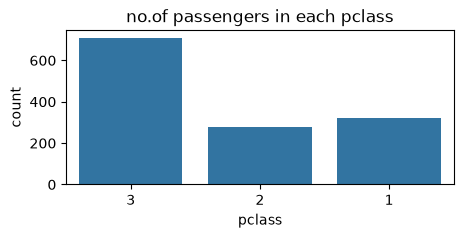

In [170]:
# sns.countplot(df, x=df['pclass'])

plt.figure(figsize = (5,2))      # {width,height}
sns.countplot(data = df, x = 'pclass' , order = [3,2,1])
plt.title('no.of passengers in each pclass')
plt.show()

# Observation:-

1. Most of the passengers are travelling in 'Pclass-3' followed by 'Pclass-1', 'Pclass -2 '

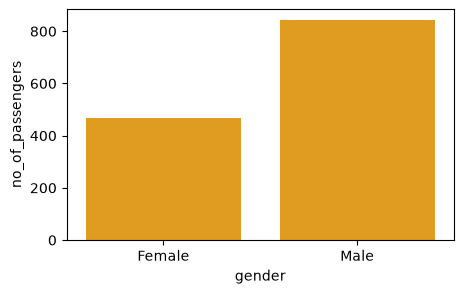

In [145]:
plt.figure(figsize=(5,3))        # (width,height)
sns.countplot(df,x='gender',color='orange')
plt.ylabel('no_of_passengers')
plt.show()

2. 'plot the portion/percentage of passengers in each Pclass'.

In [146]:
df['pclass'].value_counts()

pclass
3    709
1    323
2    277
Name: count, dtype: int64

In [147]:
p=df['pclass'].value_counts()
print(p.index)
print(p.values)

Index([3, 1, 2], dtype='int64', name='pclass')
[709 323 277]


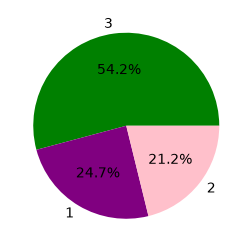

In [148]:
plt.figure(figsize=(3,5))  
plt.pie(x=p.values,autopct='%.1f%%',labels=p.index,colors={'purple','green','pink'})
plt.show()

4. Distribution of passenger's age

In [149]:
import numpy as np

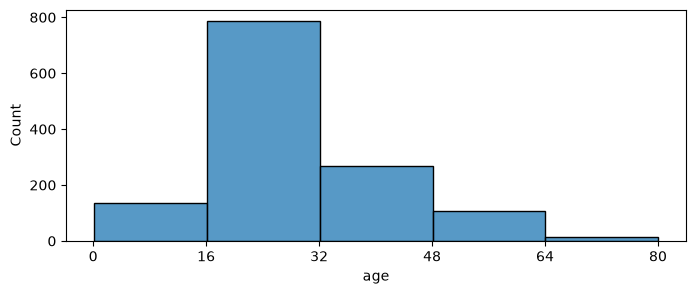

In [150]:
plt.figure(figsize=(8,3))           #(width,height)
sns.histplot(df,x='age',bins=5)
nums=np.linspace(0,80,6)

plt.xticks(nums)
plt.show()

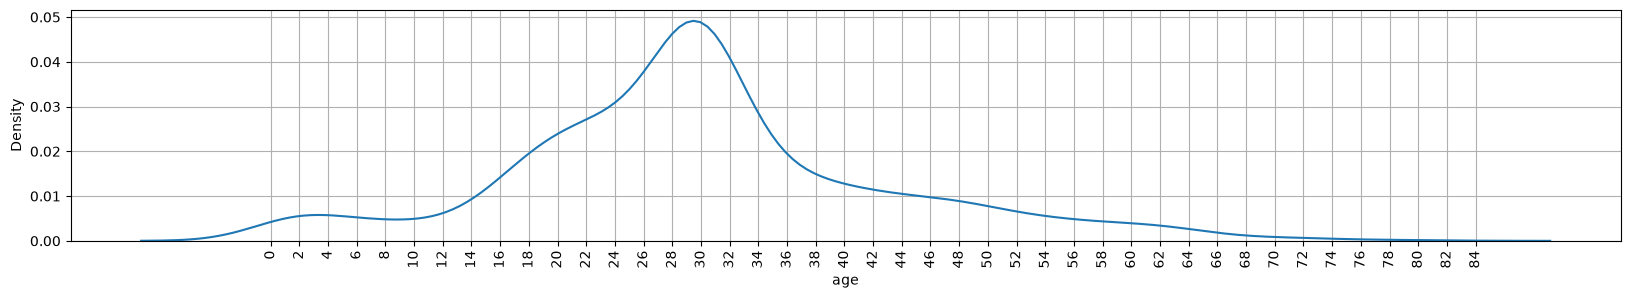

In [151]:
plt.figure(figsize=(20,3))                  #(width,height)
sns.kdeplot(df,x='age') 
plt.xticks(range(0,85,2),rotation=90)       # KDE:- Kernel Density Estimation
plt.grid()
plt.show()

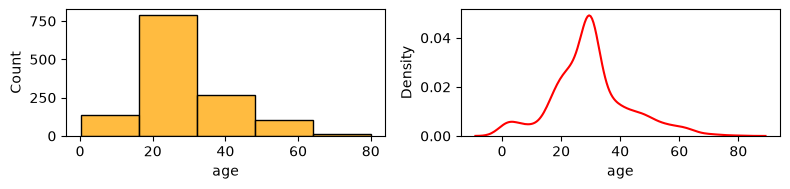

In [152]:
f,a=plt.subplots(nrows=1,ncols=2,figsize=(8,2))
sns.histplot(df,x='age',bins=5,ax=a[0],color='orange')                        # Here a is 'axes number'
sns.kdeplot(df,x='age',ax=a[1],color='red')                  # Kernel density estimation
plt.tight_layout()

5. plot the total_fare for each pclass

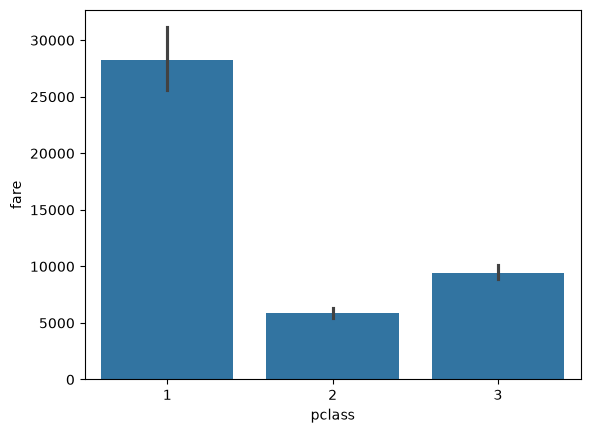

In [153]:
plt.Figure(figsize = (10,3))  # (width,height)
sns.barplot (df, x ='pclass', y = 'fare', estimator = 'sum')
plt.show()

The total fare amount is higher from pclass1 followed by pclass 3 and pclass 2

6. Plot gender wise total fare

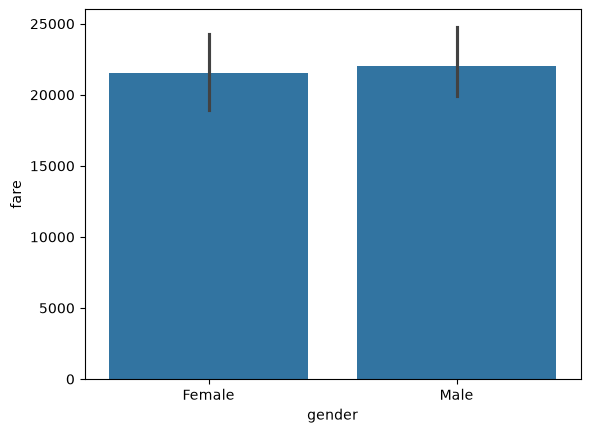

In [154]:
plt.Figure(figsize = (10,3))  # (width,height)
sns.barplot (df, x ='gender', y = 'fare', estimator = 'sum')
plt.show()

7. Plot pclass wise no of male and female passengers 

<Axes: xlabel='pclass', ylabel='count'>

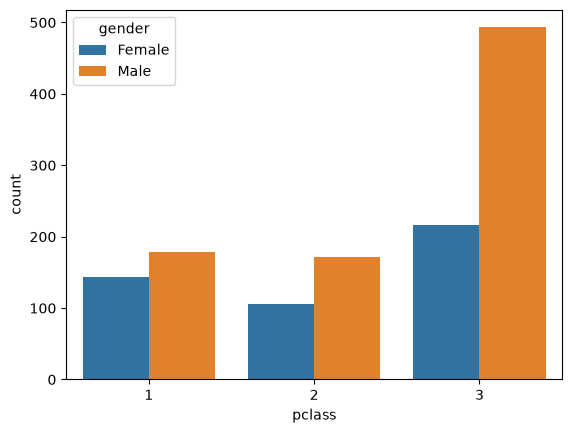

In [155]:
plt.Figure(figsize = (10,3))   # (width,height)
sns.countplot(df, x = 'pclass', hue = 'gender')

# Observation 
1. The total fare of male and female is almost equal or same
2. Male Passengers are more in all pclass 
3. Most of the male passengers are prefering pclass 3

8. plot pclass wise total fare of male and female passengers

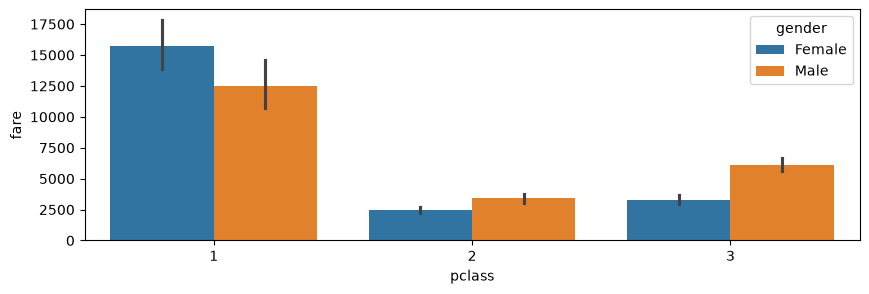

In [156]:
plt.figure(figsize = (10,3))
sns.barplot(df, x = 'pclass', y='fare', estimator = 'sum', hue = 'gender')
plt.show()

# Observation
1. pclass1 male and female passengers total fare is higher regardless of no of passengers (Because pclass1 fare is expensive)

9. Plot the relationship between age and fare

<Axes: xlabel='age', ylabel='fare'>

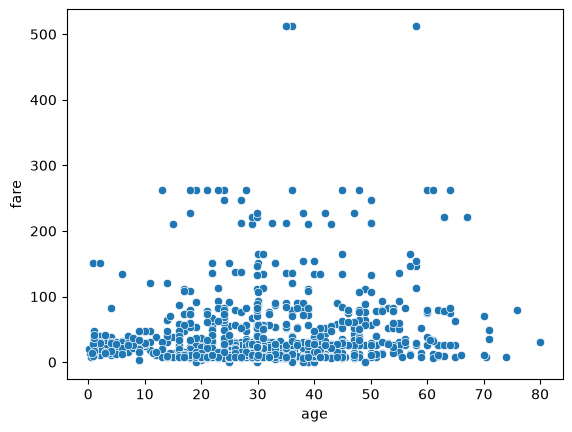

In [157]:
sns.scatterplot(df, x = 'age', y = 'fare')

10. Get the co-relation to the all numerical columns

In [158]:
c = df.corr(numeric_only = True)

<Axes: >

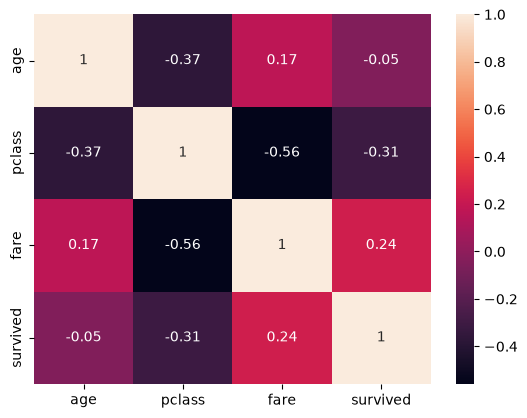

In [159]:
sns.heatmap(c, annot = True)

<Axes: xlabel='age'>

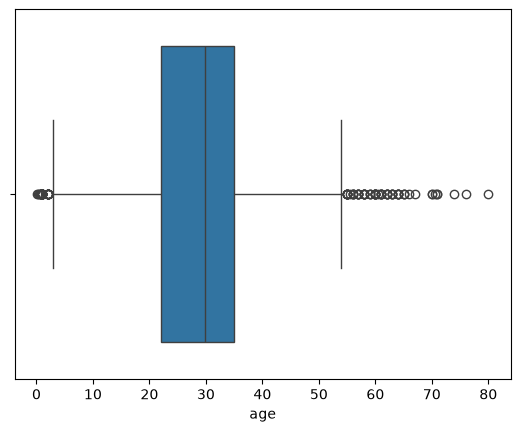

In [160]:
sns.boxplot(df, x='age')

<Axes: xlabel='fare'>

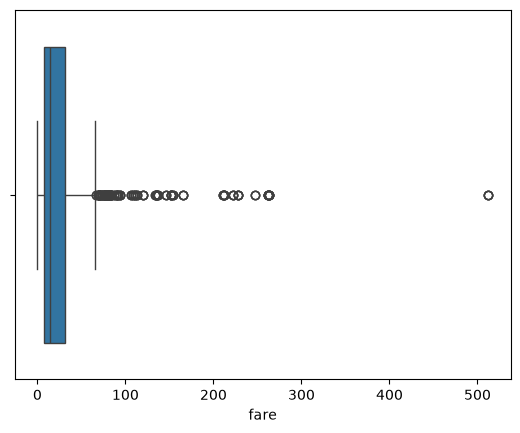

In [161]:
sns.boxplot(df, x = 'fare')

<Axes: xlabel='age', ylabel='gender'>

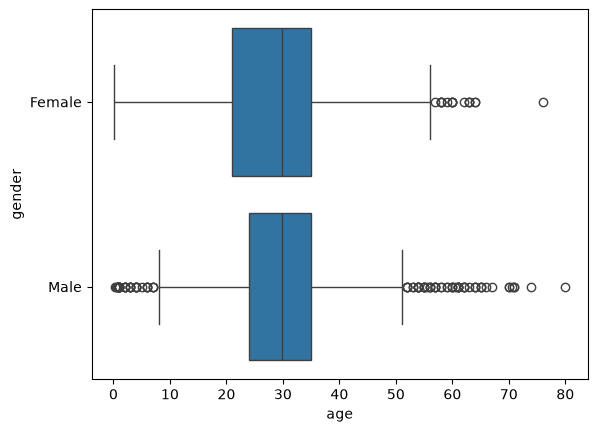

In [162]:
sns.boxplot(df, x = 'age', y ='gender')

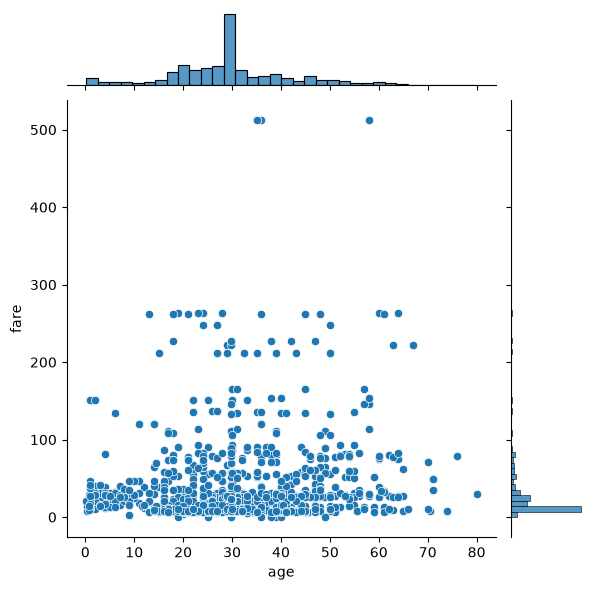

In [163]:
sns.jointplot(df, x = 'age', y = 'fare')

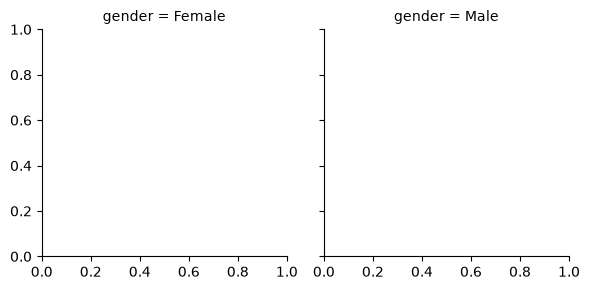

In [164]:
fg = sns.FacetGrid(df, col = 'gender')

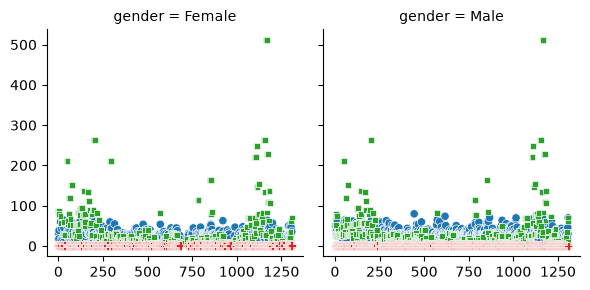

In [165]:
fg = sns.FacetGrid(df, col = 'gender')
fg.map_dataframe(sns.scatterplot)

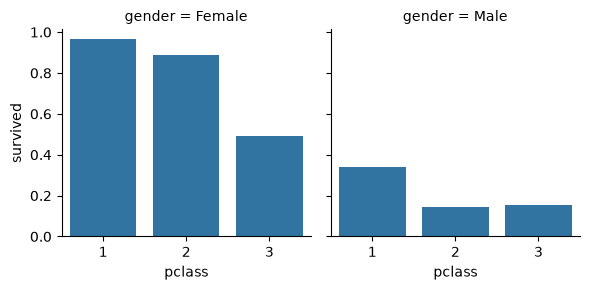

In [166]:
fg = sns.FacetGrid(df, col = 'gender')
fg.map_dataframe(sns.barplot, x = 'pclass', y = 'survived', estimator = 'mean', errorbar = None)

pclass has 34% influence on survival

# 5. Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on the Titanic dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

- Cleaned the dataset and handled missing values.
- Created new features such as family count and passenger title.
- Analyzed survival rates based on passenger class and gender.
- Used different visualizations to identify patterns and relationships in the data.

**Key Takeaway:** This project helped me improve my data cleaning, data analysis, and visualization skills while gaining insights into Titanic passenger survival patterns.